# 1. Single Non-Dispersive Interface: Analytical Fresnel Equations & EMUstack S-Matrix

## Physical Motivation & Learning Objectives
When plane waves encounter a planar interface separating two optical media of refractive indices $n_1$ and $n_2$, light undergoes reflection and transmission governed by **Fresnel's equations**. In EMUstack, homogeneous layers are modeled via the analytic `ThinFilm` class, which expands fields into a spatial Fourier series of plane-wave diffraction orders.

In this tutorial, you will learn:
1. How to define non-dispersive planar layers (`objects.ThinFilm`) and incident illumination (`objects.Light`).
2. Why an artificial unit-cell period ($\Lambda$) is assigned to homogeneous layers, and how `max_order_PWs` governs diffraction orders.
3. How to verify numerical reflection against analytical Fresnel formulas.
4. How to inspect propagation constants ($k_z$) and scattering matrices ($R_{\mathrm{net}}$).



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



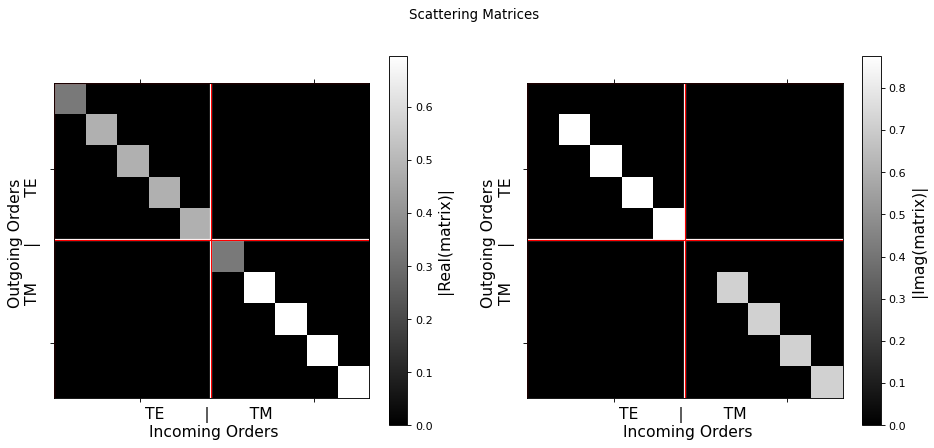

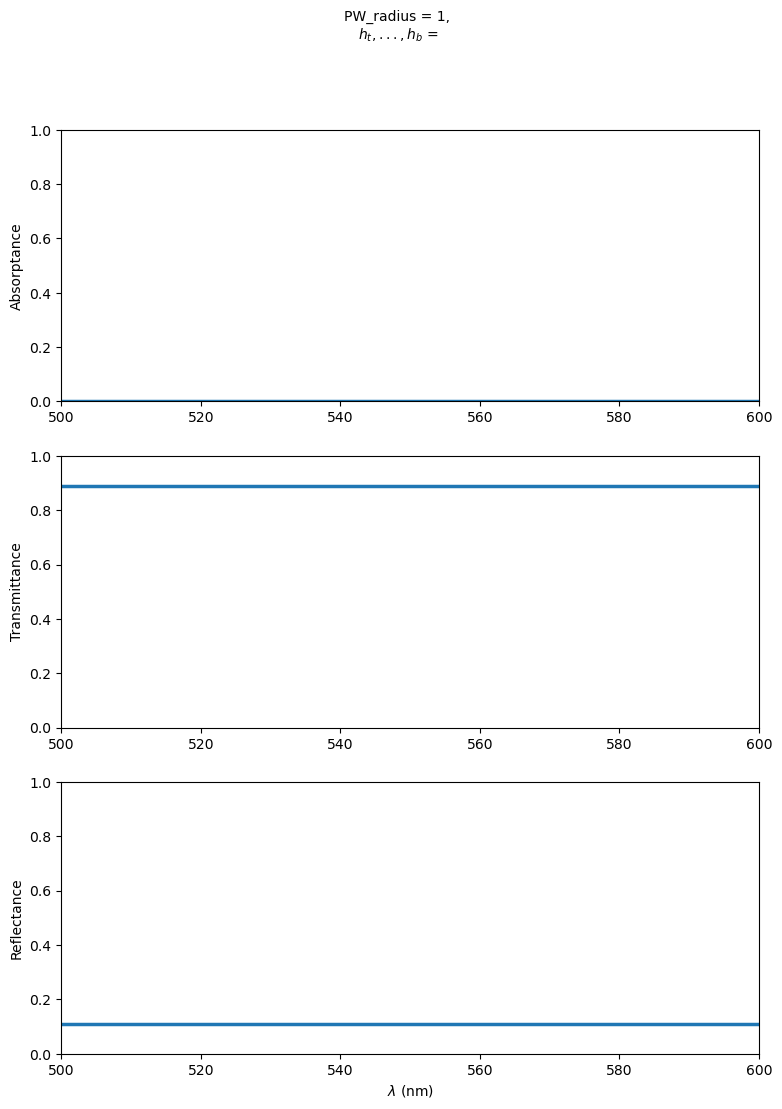

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 500.0
wl_2 = 600.0
no_wl_1 = 21
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0, n_inc=1.5) for wl in wavelengths]

period = 300.0
superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.5 + 0.0j))
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(3.0 + 0.0j))

def simulate_stack(light):
    sim_sup = superstrate.calc_modes(light)
    sim_sub = substrate.calc_modes(light)
    stk = Stack((sim_sub, sim_sup))
    stk.calc_scat(pol='TE')
    return stk

stacks_list = [simulate_stack(l) for l in light_list]

# Retrieve propagation constants
betas_sup = stacks_list[0].layers[1].k_z
betas_sub = stacks_list[-1].layers[0].k_z

# Visualize scattering matrix at last wavelength
R_interface = stacks_list[-1].R_net
fig_mat = plotting.vis_scat_mats(R_interface)
plt.show()

# Transmission and Reflection spectra
figs_tra = plotting.t_r_a_plots(stacks_list)
plt.show()


## Illumination & Layer Definitions

We simulate a normal-incidence beam ($	heta = 0^\circ, \phi = 0^\circ$) across $\lambda \in [500, 600]$ nm. The superstrate has refractive index $n_1 = 1.5$ and the substrate has $n_2 = 3.0$.

For homogeneous planar films, an artificial period $\Lambda = 300$ nm is chosen. All layers in a simulation stack must share the same period.


## Stack Scattering Matrix Evaluation

We calculate the eigenmodes of each layer and assemble the 2-layer `Stack`. Because the media are non-dispersive, the reflectance is wavelength-independent.


## Analytical Verification Against Fresnel Reflection

At normal incidence, the Fresnel reflection coefficient is:
$$r = \frac{n_1 - n_2}{n_1 + n_2} = \frac{1.5 - 3.0}{1.5 + 3.0} = \frac{-1.5}{4.5} = -\frac{1}{3}$$
$$R_{\mathrm{analytical}} = |r|^2 = \frac{1}{9} \approx 0.111111$$


## Scattering Matrix Visualization & Reflection Spectra

Because both layers are homogeneous, the reflection scattering matrix $R_{\mathrm{net}}$ is strictly diagonal (no coupling between diffraction orders).


## Physical Interpretation
- The reflectance is flat across the spectrum at exactly $R = 1/9 \approx 11.11\%$ and transmission is $T = 1 - R = 88.89\%$.
- No absorption occurs because both materials have zero imaginary refractive index.
- The off-diagonal blocks of the scattering matrix remain zero to machine precision, confirming that homogeneous planar interfaces conserve transverse momentum.
